# Earnings estimator: analysis notebook

Runs the SQL pipeline on the synthetic data, then shows the data checks, the trimming, the two levers and an example estimate. Run `python data/generate.py` first.

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
from run_pipeline import build

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = Path('images'); IMG.mkdir(exist_ok=True)
con = build()

## 1. Data checks

Each row compares the naive version of a step with the one the model uses.

In [2]:
checks = con.table('data_checks').df()
checks[['check_id', 'check_name', 'naive_value', 'model_value']].round(2)

,check_id,check_name,naive_value,model_value
0,1,Reward rows after adding profession,776663.00,525044.00
1,2,Eligible panelists,31372.00,46571.00
2,3,"P75 monthly earnings, all eligible (USD)",163.26,132.48
3,4,Cells below the minimum size (%),50.00,0.00
4,5,Mean / median monthly earnings,1.45,1.25


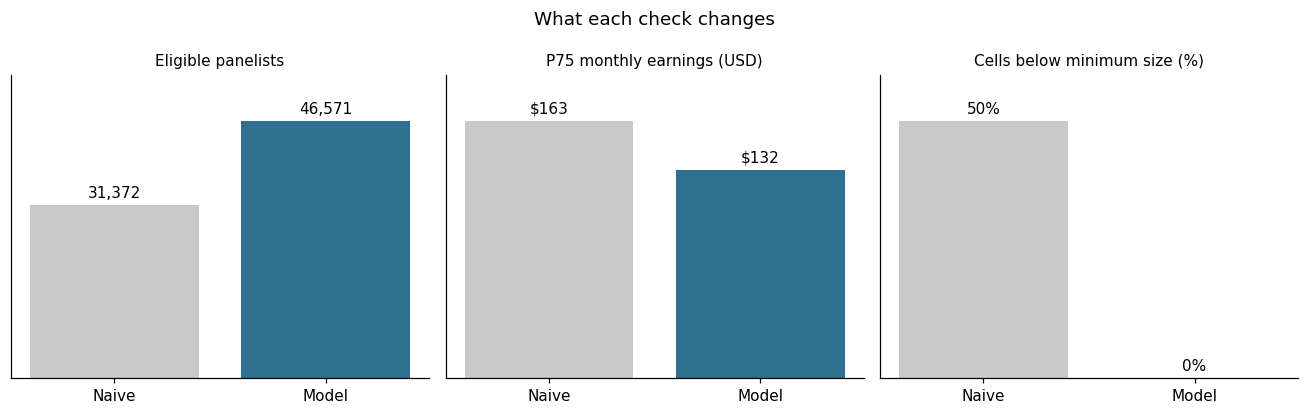

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
panels = [(2, 'Eligible panelists', '{:,.0f}'), (3, 'P75 monthly earnings (USD)', '${:,.0f}'),
          (4, 'Cells below minimum size (%)', '{:.0f}%')]
for ax, (cid, title, fmt) in zip(axes, panels):
    row = checks.set_index('check_id').loc[cid]
    vals = [row.naive_value, row.model_value]
    bars = ax.bar(['Naive', 'Model'], vals, color=['#c9c9c9', '#2f6f8f'])
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=3)
    ax.set_ylim(0, max(vals) * 1.18); ax.set_title(title, fontsize=10); ax.set_yticks([])
fig.suptitle('What each check changes', fontsize=12)
fig.tight_layout(); fig.savefig(IMG / 'checks.png', bbox_inches='tight')

## 2. Trimming the tails

The bands are built on panelists between the 15th and 97th percentile of monthly earnings.

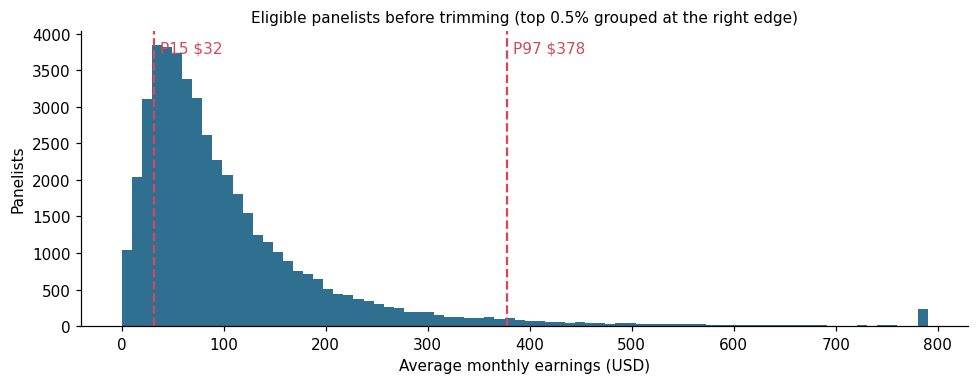

In [4]:
earn = con.table('panelist_earnings').df()
lo, hi = con.execute('SELECT lower_limit, upper_limit FROM trim_limits').fetchone()
cap = earn.usd_per_month.quantile(0.995)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(earn.usd_per_month.clip(upper=cap), bins=80, color='#2f6f8f')
for x, label in [(lo, 'P15'), (hi, 'P97')]:
    ax.axvline(x, color='#d1495b', ls='--')
    ax.annotate(f'{label} ${x:,.0f}', (x, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, -14), textcoords='offset points', color='#d1495b')
ax.set_xlabel('Average monthly earnings (USD)'); ax.set_ylabel('Panelists')
ax.set_title('Eligible panelists before trimming (top 0.5% grouped at the right edge)', fontsize=10)
fig.tight_layout(); fig.savefig(IMG / 'trimming.png', bbox_inches='tight')

## 3. Levers: observed vs applied

The applied factor keeps 60% of the observed distance from 1.0, rounded to one decimal.

,lever,level,panelists,avg_usd_per_month,observed_ratio,applied_factor
0,visits,Light,11042,71.87,0.680,0.8
1,visits,Regular,20819,105.73,1.000,1.0
2,visits,Frequent,6326,179.44,1.697,1.4
3,study time,Short,12510,75.61,0.779,0.9
4,study time,Medium,12916,97.10,1.000,1.0
5,study time,Long,12761,151.23,1.558,1.3


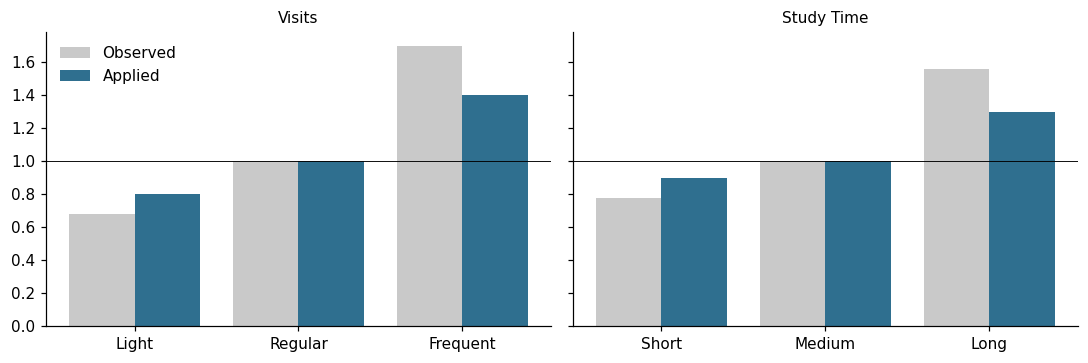

In [5]:
lev = con.table('levers').df()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, ['visits', 'study time']):
    m = lev[lev.lever == name]
    x = range(len(m))
    ax.bar([i - 0.2 for i in x], m.observed_ratio, 0.4, label='Observed', color='#c9c9c9')
    ax.bar([i + 0.2 for i in x], m.applied_factor, 0.4, label='Applied', color='#2f6f8f')
    ax.set_xticks(list(x)); ax.set_xticklabels(m.level); ax.axhline(1, color='black', lw=0.6)
    ax.set_title(name.title(), fontsize=10)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(IMG / 'levers.png', bbox_inches='tight')
lev

## 4. Example estimate and peer benchmark

In [6]:
con.execute("""
    SELECT visit_level, time_band, low_usd_month, typical_usd_month, high_usd_month, typical_usd_year
    FROM estimates
    WHERE profession = 'Data & Analytics' AND market = 'United States'
    ORDER BY CASE visit_level WHEN 'Light' THEN 1 WHEN 'Regular' THEN 2 ELSE 3 END,
             CASE time_band WHEN 'Short' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END
""").df()

,visit_level,time_band,low_usd_month,typical_usd_month,high_usd_month,typical_usd_year
0,Light,Short,59.0,87.0,132.0,1040.0
1,Light,Medium,66.0,96.0,147.0,1150.0
2,Light,Long,85.0,125.0,191.0,1500.0
3,Regular,Short,74.0,108.0,166.0,1300.0
4,Regular,Medium,82.0,120.0,184.0,1440.0
5,Regular,Long,107.0,156.0,239.0,1880.0
6,Frequent,Short,104.0,151.0,232.0,1820.0
7,Frequent,Medium,115.0,168.0,258.0,2020.0
8,Frequent,Long,150.0,219.0,335.0,2630.0


In [7]:
con.table('peer_benchmarks').df()

,profession,panelists,median_usd_month,mean_usd_month,median_visits_week,median_study_minutes_week
0,Legal,2345,109.0,128.0,0.4,4.0
1,Data & Analytics,3175,101.0,122.0,0.4,4.0
2,Software Engineering,6413,100.0,120.0,0.4,4.0
3,Finance,4842,97.0,118.0,0.4,4.0
4,Healthcare,4049,95.0,117.0,0.4,4.0
5,Marketing,3762,79.0,100.0,0.4,4.0
6,Operations,4062,76.0,96.0,0.4,4.0
7,Sales,3651,74.0,93.0,0.4,4.0
8,Other,2890,70.0,90.0,0.5,5.0
9,Education,2998,69.0,90.0,0.5,5.0
